In [1]:
import kagglehub
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
import string
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import re
from wordcloud import STOPWORDS

c:\Users\asus\Desktop\nlp\spam_detection\nlp_spam_detect\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#variables i will need
lem=WordNetLemmatizer()
port=PorterStemmer()

In [3]:

# Download latest version
df=pd.read_csv("sms_spam_indo.csv",usecols=['Kategori','Pesan'])
print(df.shape)
df.head(10)


(1143, 2)


,Kategori,Pesan
0,spam,Plg Yth: Simcard anda mendptkan bonus poin plu...
1,ham,Iya ih ko sedih sih gtau kapan lg ke bandung :(
2,ham,Kalau mau bikin model/controller mending per a...
3,ham,Selamat nama1. Semoga selalu menempuh hidup ya...
4,spam,Tingkatkan nilai isi ulang Anda selanjutnya mi...
5,spam,Uangnya di Trnsfer di BNI ini aja a/n RASTINA ...
6,spam,PESAN RESMI Selamat NO Simcard anda M-dptkam h...
7,spam,"Sy RUDI di jambi, bgi tman2 yg sering kalah To..."
8,spam,Tri berBAGI bonus PULSA di bulan pernuh berkah...
9,ham,silahkan berkas dambil di ruang saya


In [4]:
#look at length of comments
df[df['Pesan'].str.len()<20]

,Kategori,Pesan
153,ham,Abis maghrib yaa
156,ham,Yang sinonim bukan?
352,ham,nama1 ke pt. inti?
407,ham,Ada nya instagram
704,ham,nama1 helmkuuuu.:'(
713,ham,Waaah keren kang
922,ham,Aku di pt. DI
1052,ham,bntr lagi pulang


In [5]:
#see summary of length
#plot histogram of length of pesan

In [6]:
# Get the highest value
highest_value = df['Pesan'].str.len().max()
print("Highest Value:", highest_value)

Highest Value: 434


In [7]:
highest_value = df['Pesan'].str.len().sort_values(ascending=False)
highest_value.head()


408     434
221     431
751     421
1125    391
329     376
Name: Pesan, dtype: int64

In [8]:
ind_stopwords=stopwords.words("indonesian")
stopwords = set(ind_stopwords)

In [9]:
def showCloud(dataframe):
    text = ' '.join(dataframe['Pesan'].astype(str).tolist())

    text = re.sub(r'[^A-Za-z\s]', '', text)

    text = text.lower()
    general_words={'enron','ect','cc','kaminski','vince'}
    banned_words=stopwords.union(general_words)
    text = ' '.join(word for word in text.split() if word not in banned_words)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title("Word Cloud")
    plt.show()

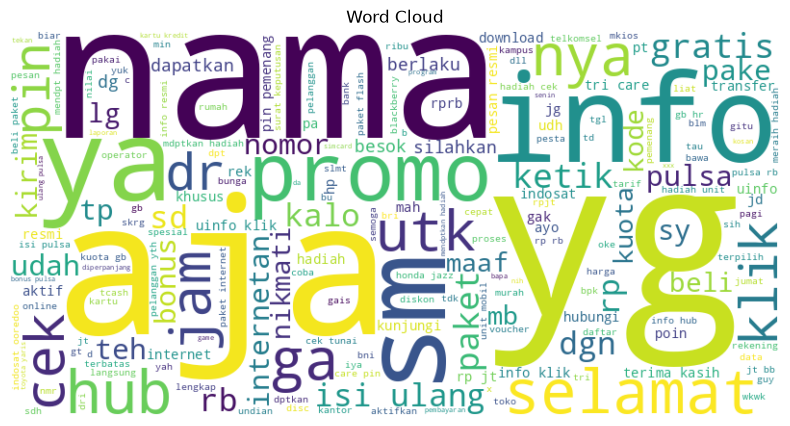

In [10]:
showCloud(df)

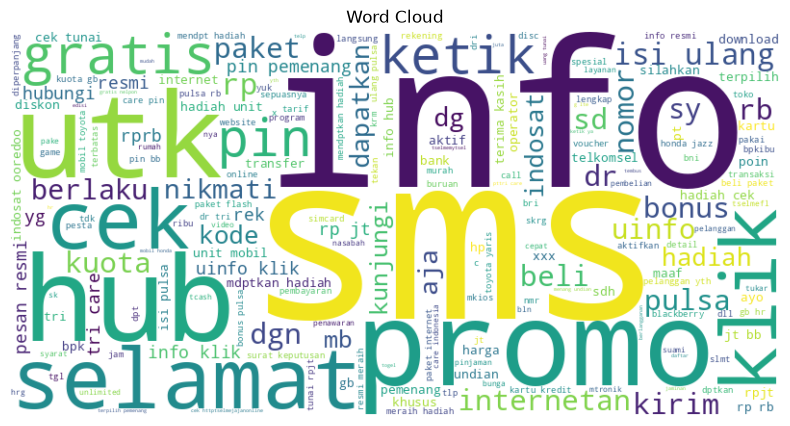

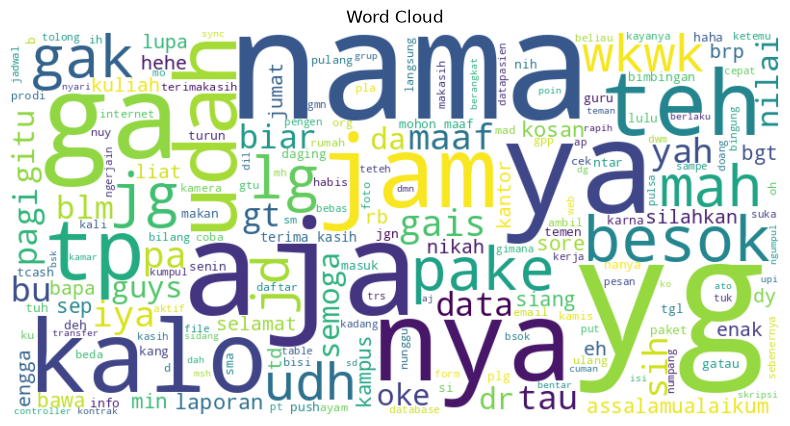

In [11]:
#repeat with spam and nonspam categories
#spam
spam_df = df[df['Kategori']=='spam']
showCloud(spam_df)

ham_df = df[df['Kategori']=='ham']
showCloud(ham_df)

In [12]:
#to do list: remove the name vince j kaminski, enron, shirley crenshaw